In [7]:
# Updating package with new changes
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from src.visualizer import *

In [3]:
#  Repetition 1: 5 packages and 2 trucks
from src.engine import *
from src.solvers.hill_climbing import SteepestAscent
import matplotlib.pyplot as plt

# Input packages and trucks
pkgs = [
   # Package(id, width, length, height, value, weight, is_fragile, eta) 
   Package("A", 3, 4, 1, 60, 5, False, 3), 
   Package("B", 2, 2, 2, 40, 3, True, 1),
   Package("C", 1, 1, 1, 20, 1, False, 2),
   Package("D", 4, 5, 2, 80, 7, True, 4),
   Package("E", 2, 3, 1, 50, 4, False, 5)
]
# Truck(id, width, length, height, max_capacity)
trucks = [Truck("a", 10, 20, 5, 25), Truck("b", 8, 15, 4, 30)]

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

Initial State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Unassigned
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Unassigned
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Unassigned
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Truck a at (6, 8, 0)
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Unassigned



In [4]:
# Repetition 2: 15 packages and 3 trucks
# Fixed seeds make each generated dataset reproducible when this cell is rerun.
import random

rng_2 = random.Random(106)
pkgs_2 = [
    Package(
        f"P{i + 1}", # id
        rng_2.randint(1, 5),  # width
        rng_2.randint(1, 5),  # length
        rng_2.randint(1, 5),  # height
        rng_2.randint(10, 100),  # value
        rng_2.randint(2, 10),  # weight
        rng_2.choice([True, False]),  # is_fragile
        rng_2.randint(1, 10),  # eta
    )
    for i in range(15)
]
trucks_2 = [
    Truck(
        f"T{i + 1}", # id
        rng_2.randint(7, 10),  # width
        rng_2.randint(10, 20),  # length
        rng_2.randint(7, 10),  # height
        rng_2.randint(30, 50),  # max_capacity
    )
    for i in range(3)
]
initial_state_2 = State(pkgs_2, trucks_2, init="random_feasible")

# Repetition 3: 7 packages and 1 truck
rng_3 = random.Random(135)
pkgs_3 = [
    Package(
        f"P{i + 1}", # id
        rng_3.randint(1, 5),  # width
        rng_3.randint(1, 5),  # length
        rng_3.randint(1, 5),  # height
        rng_3.randint(10, 100),  # value
        rng_3.randint(2, 10),  # weight
        rng_3.choice([True, False]),  # is_fragile
        rng_3.randint(1, 10),  # eta
    )
    for i in range(7)
]
trucks_3 = [
    Truck(
        f"T1", # id
        rng_3.randint(7, 10),  # width
        rng_3.randint(10, 20),  # length
        rng_3.randint(7, 10),  # height
        rng_3.randint(30, 50),  # max_capacity
    )
]
initial_state_3 = State(pkgs_3, trucks_3, init="random_feasible")

print("Generated random datasets for repetition 2 and 3:")
print(f"Repetition 2: {len(pkgs_2)} packages, {len(trucks_2)} trucks")
print(f"Repetition 3: {len(pkgs_3)} packages, {len(trucks_3)} trucks")

Generated random datasets for repetition 2 and 3:
Repetition 2: 15 packages, 3 trucks
Repetition 3: 7 packages, 1 trucks


Packages List: [Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3), Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1), Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2), Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4), Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5)]
Trucks List: [Truck a (dim=10x20x5, max_capacity=25), Truck b (dim=8x15x4, max_capacity=30)]
Initial State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck b at (7, 11, 0)
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Unassigned
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Truck a at (3, 19, 0)
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Truck a at (5, 1, 0)
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Truck a at (7, 3, 0)

Final State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck b at (7, 1

NameError: name 'local_x' is not defined

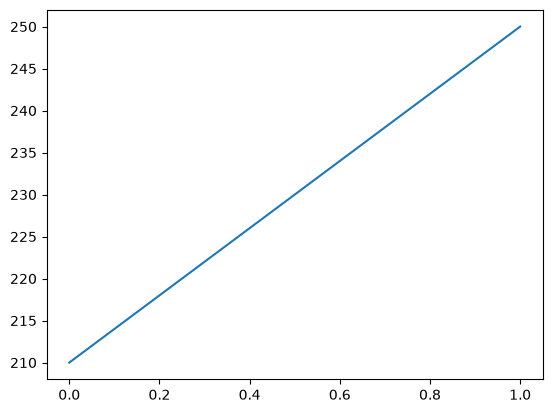

In [9]:
# Steepest Ascent Hill Climbing, repetition 1
from src.engine import *
from src.solvers.hill_climbing import SteepestAscent
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = [
   # Package(id, width, length, height, value, weight, is_fragile, eta) 
   Package("A", 3, 4, 1, 60, 5, False, 3), 
   Package("B", 2, 2, 2, 40, 3, True, 1),
   Package("C", 1, 1, 1, 20, 1, False, 2),
   Package("D", 4, 5, 2, 80, 7, True, 4),
   Package("E", 2, 3, 1, 50, 4, False, 5)
]
print("Packages List:",pkgs) # List of packages
# Truck(id, width, length, height, max_capacity)
trucks = [Truck("a", 10, 20, 5, 25), Truck("b", 8, 15, 4, 30)]
print("Trucks List:", trucks) # List of trucks

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Steepest Ascent Hill Climbing
solver_steepest_ascent = SteepestAscent(obj, max_iterations = 100)
results_steepest_ascent = solver_steepest_ascent.solve(initial_state)

# Getting the results
print("Final State:", results_steepest_ascent.final_state) # Output: Final State
print("Final Objective Value:", results_steepest_ascent.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_steepest_ascent.runtime, "sec") # Output: Runtime
print("Iterations:", results_steepest_ascent.total_iterations) # Output: Iterations
plt.plot(results_steepest_ascent.objective_history) # Output: Plot of Objective Value over Iterations
draw_state(initial_state)
draw_state(results_steepest_ascent.final_state)

Packages List: [Package P1 (dim=4x1x5, weight=9, value=77, fragile=True, eta=5), Package P2 (dim=1x2x4, weight=8, value=56, fragile=False, eta=5), Package P3 (dim=2x4x3, weight=4, value=71, fragile=True, eta=5), Package P4 (dim=3x4x3, weight=6, value=19, fragile=False, eta=6), Package P5 (dim=2x2x4, weight=2, value=20, fragile=True, eta=6), Package P6 (dim=1x2x3, weight=10, value=66, fragile=False, eta=10), Package P7 (dim=3x4x4, weight=5, value=64, fragile=True, eta=3), Package P8 (dim=4x2x2, weight=5, value=41, fragile=False, eta=10), Package P9 (dim=5x2x2, weight=6, value=50, fragile=True, eta=10), Package P10 (dim=3x5x4, weight=8, value=78, fragile=True, eta=7), Package P11 (dim=2x5x3, weight=8, value=59, fragile=True, eta=3), Package P12 (dim=5x1x3, weight=10, value=78, fragile=True, eta=2), Package P13 (dim=5x4x4, weight=5, value=76, fragile=True, eta=4), Package P14 (dim=1x4x1, weight=5, value=57, fragile=False, eta=4), Package P15 (dim=2x1x1, weight=6, value=79, fragile=False, 

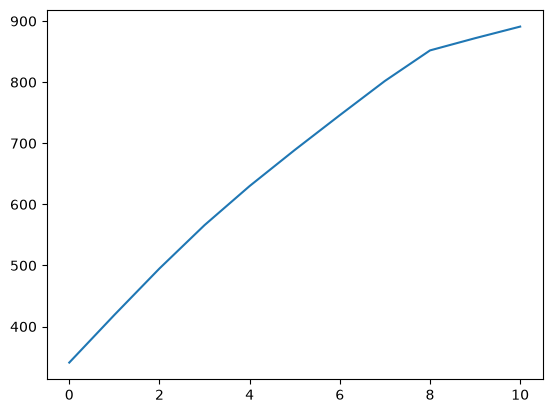

In [6]:
# Steepest Ascent Hill Climbing, repetition 2
from src.engine import *
from src.solvers.hill_climbing import SteepestAscent
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = pkgs_2
print("Packages List:",pkgs) # List of packages
# Truck(id, width, length, height, max_capacity)
trucks = trucks_2
print("Trucks List:", trucks) # List of trucks

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Steepest Ascent Hill Climbing
solver_steepest_ascent = SteepestAscent(obj, max_iterations = 100)
results_steepest_ascent = solver_steepest_ascent.solve(initial_state)

# Getting the results
print("Final State:", results_steepest_ascent.final_state) # Output: Final State
print("Final Objective Value:", results_steepest_ascent.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_steepest_ascent.runtime, "sec") # Output: Runtime
print("Iterations:", results_steepest_ascent.total_iterations) # Output: Iterations
plt.plot(results_steepest_ascent.objective_history) # Output: Plot of Objective Value over Iterations

Packages List: [Package P1 (dim=3x5x3, weight=6, value=72, fragile=True, eta=8), Package P2 (dim=3x1x5, weight=7, value=29, fragile=False, eta=6), Package P3 (dim=3x3x3, weight=6, value=85, fragile=False, eta=5), Package P4 (dim=1x2x3, weight=6, value=10, fragile=True, eta=5), Package P5 (dim=3x3x3, weight=5, value=19, fragile=True, eta=4), Package P6 (dim=2x4x5, weight=2, value=25, fragile=False, eta=7), Package P7 (dim=3x2x1, weight=6, value=40, fragile=True, eta=4)]
Trucks List: [Truck T1 (dim=10x18x8, max_capacity=40)]
Initial State: State:
  Package P1 (dim=3x5x3, weight=6, value=72, fragile=True, eta=8) -> Unassigned
  Package P2 (dim=3x1x5, weight=7, value=29, fragile=False, eta=6) -> Unassigned
  Package P3 (dim=3x3x3, weight=6, value=85, fragile=False, eta=5) -> Unassigned
  Package P4 (dim=1x2x3, weight=6, value=10, fragile=True, eta=5) -> Unassigned
  Package P5 (dim=3x3x3, weight=5, value=19, fragile=True, eta=4) -> Unassigned
  Package P6 (dim=2x4x5, weight=2, value=25, fr

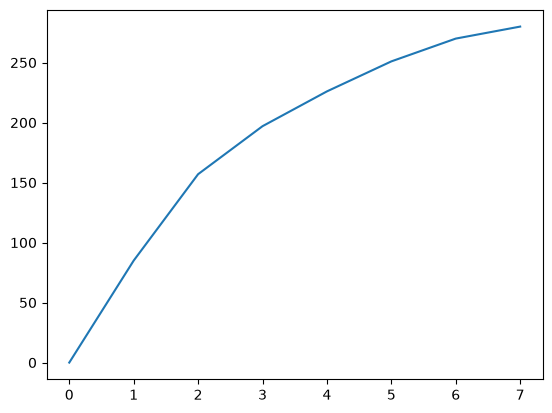

In [ ]:
# Steepest Ascent Hill Climbing, repetition 3
from src.engine import *
from src.solvers.hill_climbing import SteepestAscent
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = pkgs_3
print("Packages List:", pkgs) # List of packages
# Truck(id, width, length, height, max_capacity)
trucks = trucks_3
print("Trucks List:", trucks) # List of trucks

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Steepest Ascent Hill Climbing
solver_steepest_ascent = SteepestAscent(obj, max_iterations = 100)
results_steepest_ascent = solver_steepest_ascent.solve(initial_state)

# Getting the results
print("Final State:", results_steepest_ascent.final_state) # Output: Final State
print("Final Objective Value:", results_steepest_ascent.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_steepest_ascent.runtime, "sec") # Output: Runtime
print("Iterations:", results_steepest_ascent.total_iterations) # Output: Iterations
plt.plot(results_steepest_ascent.objective_history) # Output: Plot of Objective Value over Iterations

Packages List: [Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3), Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1), Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2), Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4), Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5)]
Trucks List: [Truck a (dim=10x20x5, max_capacity=25), Truck b (dim=8x15x4, max_capacity=30)]
Initial State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Unassigned
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Unassigned
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Unassigned
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Truck a at (2, 18, 0)
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Truck a at (7, 16, 0)

Final State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck a at (0, 2, 1)
  Package B (di

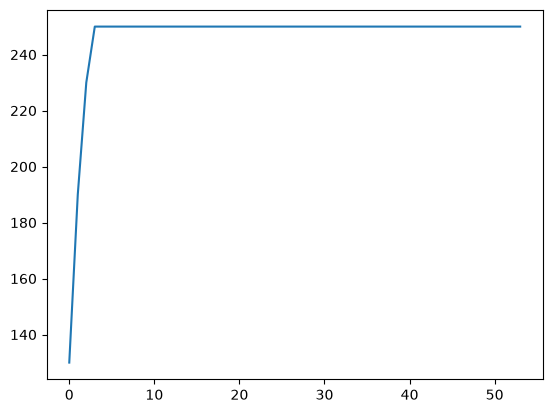

In [ ]:
# Sideways Move Hill Climbing, repetition 1
from src.engine import *
from src.solvers.hill_climbing import SidewaysMove
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = [
   # Package(id, width, length, height, value, weight, is_fragile, eta) 
   Package("A", 3, 4, 1, 60, 5, False, 3), 
   Package("B", 2, 2, 2, 40, 3, True, 1),
   Package("C", 1, 1, 1, 20, 1, False, 2),
   Package("D", 4, 5, 2, 80, 7, True, 4),
   Package("E", 2, 3, 1, 50, 4, False, 5)
]
print("Packages List:", pkgs) # List of packages
# Truck(id, width, length, height, max_capacity)
trucks = [Truck("a", 10, 20, 5, 25), Truck("b", 8, 15, 4, 30)]
print("Trucks List:", trucks) # List of trucks

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_sideways_move = SidewaysMove(obj, max_sideways_moves = 50, max_iterations = 100)
results_sideways_move = solver_sideways_move.solve(initial_state)

# Getting the results
print("Final State:", results_sideways_move.final_state) # Output: Final State
print("Final Objective Value:", results_sideways_move.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_sideways_move.runtime, "sec") # Output: Runtime
print("Iterations:", results_sideways_move.total_iterations) # Output: Iterations
print("Total Sideways Moves:", results_sideways_move.metadata["sideways_moves"]) # Output: Total Sideways Moves
plt.plot(results_sideways_move.objective_history) # Output: Plot of Objective Value over Iterations

Packages List: [Package P1 (dim=4x1x5, weight=9, value=77, fragile=True, eta=5), Package P2 (dim=1x2x4, weight=8, value=56, fragile=False, eta=5), Package P3 (dim=2x4x3, weight=4, value=71, fragile=True, eta=5), Package P4 (dim=3x4x3, weight=6, value=19, fragile=False, eta=6), Package P5 (dim=2x2x4, weight=2, value=20, fragile=True, eta=6), Package P6 (dim=1x2x3, weight=10, value=66, fragile=False, eta=10), Package P7 (dim=3x4x4, weight=5, value=64, fragile=True, eta=3), Package P8 (dim=4x2x2, weight=5, value=41, fragile=False, eta=10), Package P9 (dim=5x2x2, weight=6, value=50, fragile=True, eta=10), Package P10 (dim=3x5x4, weight=8, value=78, fragile=True, eta=7), Package P11 (dim=2x5x3, weight=8, value=59, fragile=True, eta=3), Package P12 (dim=5x1x3, weight=10, value=78, fragile=True, eta=2), Package P13 (dim=5x4x4, weight=5, value=76, fragile=True, eta=4), Package P14 (dim=1x4x1, weight=5, value=57, fragile=False, eta=4), Package P15 (dim=2x1x1, weight=6, value=79, fragile=False, 

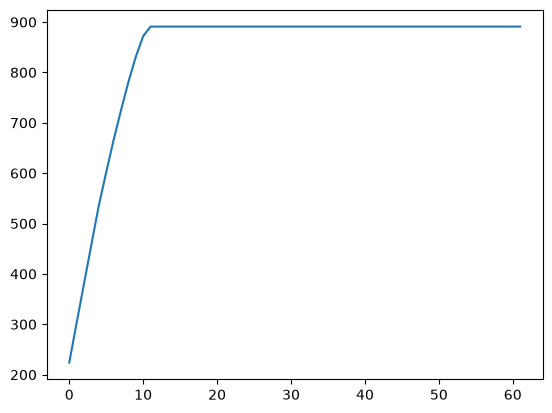

In [ ]:
# Sideways Move Hill Climbing, repetition 2
from src.engine import *
from src.solvers.hill_climbing import SidewaysMove
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = pkgs_2
print("Packages List:", pkgs) # List of packages
# Truck(id, width, length, height, max_capacity)
trucks = trucks_2
print("Trucks List:", trucks) # List of trucks

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_sideways_move = SidewaysMove(obj, max_sideways_moves = 50, max_iterations = 100)
results_sideways_move = solver_sideways_move.solve(initial_state)

# Getting the results
print("Final State:", results_sideways_move.final_state) # Output: Final State
print("Final Objective Value:", results_sideways_move.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_sideways_move.runtime, "sec") # Output: Runtime
print("Iterations:", results_sideways_move.total_iterations) # Output: Iterations
print("Total Sideways Moves:", results_sideways_move.metadata["sideways_moves"]) # Output: Total Sideways Moves
plt.plot(results_sideways_move.objective_history) # Output: Plot of Objective Value over Iterations

Packages List: [Package P1 (dim=3x5x3, weight=6, value=72, fragile=True, eta=8), Package P2 (dim=3x1x5, weight=7, value=29, fragile=False, eta=6), Package P3 (dim=3x3x3, weight=6, value=85, fragile=False, eta=5), Package P4 (dim=1x2x3, weight=6, value=10, fragile=True, eta=5), Package P5 (dim=3x3x3, weight=5, value=19, fragile=True, eta=4), Package P6 (dim=2x4x5, weight=2, value=25, fragile=False, eta=7), Package P7 (dim=3x2x1, weight=6, value=40, fragile=True, eta=4)]
Trucks List: [Truck T1 (dim=10x18x8, max_capacity=40)]
Initial State: State:
  Package P1 (dim=3x5x3, weight=6, value=72, fragile=True, eta=8) -> Truck T1 at (7, 9, 0)
  Package P2 (dim=3x1x5, weight=7, value=29, fragile=False, eta=6) -> Unassigned
  Package P3 (dim=3x3x3, weight=6, value=85, fragile=False, eta=5) -> Unassigned
  Package P4 (dim=1x2x3, weight=6, value=10, fragile=True, eta=5) -> Unassigned
  Package P5 (dim=3x3x3, weight=5, value=19, fragile=True, eta=4) -> Unassigned
  Package P6 (dim=2x4x5, weight=2, v

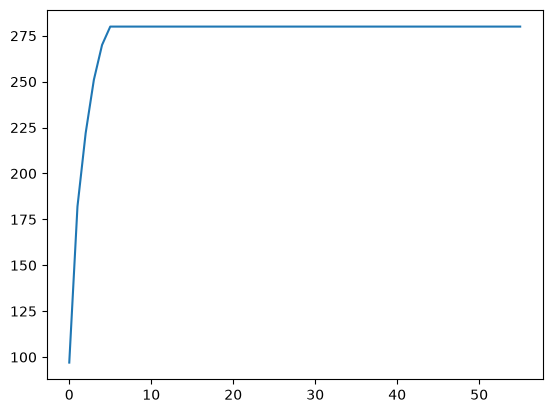

In [ ]:
# Sideways Move Hill Climbing, repetition 3
from src.engine import *
from src.solvers.hill_climbing import SidewaysMove
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = pkgs_3
print("Packages List:", pkgs) # List of packages
# Truck(id, width, length, height, max_capacity)
trucks = trucks_3
print("Trucks List:", trucks) # List of trucks

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_sideways_move = SidewaysMove(obj, max_sideways_moves = 50, max_iterations = 100)
results_sideways_move = solver_sideways_move.solve(initial_state)

# Getting the results
print("Final State:", results_sideways_move.final_state) # Output: Final State
print("Final Objective Value:", results_sideways_move.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_sideways_move.runtime, "sec") # Output: Runtime
print("Iterations:", results_sideways_move.total_iterations) # Output: Iterations
print("Total Sideways Moves:", results_sideways_move.metadata["sideways_moves"]) # Output: Total Sideways Moves
plt.plot(results_sideways_move.objective_history) # Output: Plot of Objective Value over Iterations

Packages List: [Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3), Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1), Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2), Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4), Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5)]
Trucks List: [Truck a (dim=10x20x5, max_capacity=25), Truck b (dim=8x15x4, max_capacity=30)]
Initial State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Unassigned
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Truck a at (5, 11, 0)
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Truck b at (2, 11, 0)
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Truck a at (6, 9, 0)
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Unassigned

Final State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck b at (2, 11, 0)
  Pa

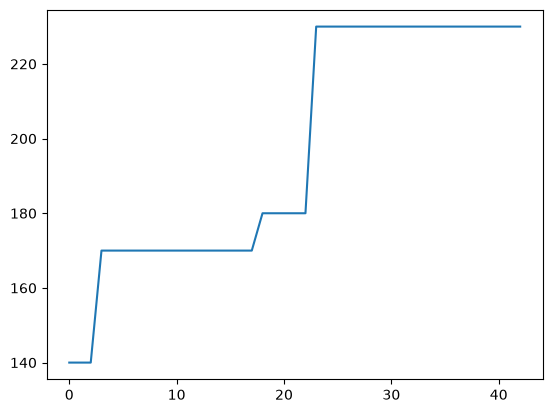

In [ ]:
# Stochastic Hill Climbing, repetition 1
from src.engine import *
from src.solvers.hill_climbing import Stochastic
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = [
   # Package(id, width, length, height, value, weight, is_fragile, eta) 
   Package("A", 3, 4, 1, 60, 5, False, 3), 
   Package("B", 2, 2, 2, 40, 3, True, 1),
   Package("C", 1, 1, 1, 20, 1, False, 2),
   Package("D", 4, 5, 2, 80, 7, True, 4),
   Package("E", 2, 3, 1, 50, 4, False, 5)
]
print("Packages List:", pkgs) # List of packages
# Truck(id, width, length, height, max_capacity)
trucks = [Truck("a", 10, 20, 5, 25), Truck("b", 8, 15, 4, 30)]
print("Trucks List:", trucks) # List of trucks

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_stochastic = Stochastic(obj, max_random_successor_iterations=20, max_iterations = 100)
results_stochastic = solver_stochastic.solve(initial_state)

# Getting the results
print("Final State:", results_stochastic.final_state) # Output: Final State
print("Final Objective Value:", results_stochastic.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_stochastic.runtime, "sec") # Output: Runtime
print("Iterations:", results_stochastic.total_iterations) # Output: Iterations
print("Random Successor Iterations:", results_stochastic.metadata["random_successor_iterations"]) # Output: Random Successor Iterations
plt.plot(results_stochastic.objective_history) # Output: Plot of Objective Value over Iterations

Packages List: [Package P1 (dim=4x1x5, weight=9, value=77, fragile=True, eta=5), Package P2 (dim=1x2x4, weight=8, value=56, fragile=False, eta=5), Package P3 (dim=2x4x3, weight=4, value=71, fragile=True, eta=5), Package P4 (dim=3x4x3, weight=6, value=19, fragile=False, eta=6), Package P5 (dim=2x2x4, weight=2, value=20, fragile=True, eta=6), Package P6 (dim=1x2x3, weight=10, value=66, fragile=False, eta=10), Package P7 (dim=3x4x4, weight=5, value=64, fragile=True, eta=3), Package P8 (dim=4x2x2, weight=5, value=41, fragile=False, eta=10), Package P9 (dim=5x2x2, weight=6, value=50, fragile=True, eta=10), Package P10 (dim=3x5x4, weight=8, value=78, fragile=True, eta=7), Package P11 (dim=2x5x3, weight=8, value=59, fragile=True, eta=3), Package P12 (dim=5x1x3, weight=10, value=78, fragile=True, eta=2), Package P13 (dim=5x4x4, weight=5, value=76, fragile=True, eta=4), Package P14 (dim=1x4x1, weight=5, value=57, fragile=False, eta=4), Package P15 (dim=2x1x1, weight=6, value=79, fragile=False, 

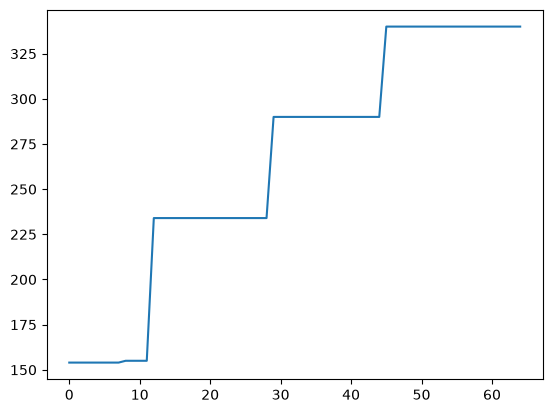

In [ ]:
# Stochastic Hill Climbing, repetition 2
from src.engine import *
from src.solvers.hill_climbing import Stochastic
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = pkgs_2
print("Packages List:", pkgs) # List of packages
# Truck(id, width, length, height, max_capacity)
trucks = trucks_2
print("Trucks List:", trucks) # List of trucks

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_stochastic = Stochastic(obj, max_random_successor_iterations=20, max_iterations = 100)
results_stochastic = solver_stochastic.solve(initial_state)

# Getting the results
print("Final State:", results_stochastic.final_state) # Output: Final State
print("Final Objective Value:", results_stochastic.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_stochastic.runtime, "sec") # Output: Runtime
print("Iterations:", results_stochastic.total_iterations) # Output: Iterations
print("Random Successor Iterations:", results_stochastic.metadata["random_successor_iterations"]) # Output: Random Successor Iterations
plt.plot(results_stochastic.objective_history) # Output: Plot of Objective Value over Iterations

Packages List: [Package P1 (dim=3x5x3, weight=6, value=72, fragile=True, eta=8), Package P2 (dim=3x1x5, weight=7, value=29, fragile=False, eta=6), Package P3 (dim=3x3x3, weight=6, value=85, fragile=False, eta=5), Package P4 (dim=1x2x3, weight=6, value=10, fragile=True, eta=5), Package P5 (dim=3x3x3, weight=5, value=19, fragile=True, eta=4), Package P6 (dim=2x4x5, weight=2, value=25, fragile=False, eta=7), Package P7 (dim=3x2x1, weight=6, value=40, fragile=True, eta=4)]
Trucks List: [Truck T1 (dim=10x18x8, max_capacity=40)]
Initial State: State:
  Package P1 (dim=3x5x3, weight=6, value=72, fragile=True, eta=8) -> Unassigned
  Package P2 (dim=3x1x5, weight=7, value=29, fragile=False, eta=6) -> Truck T1 at (2, 15, 0)
  Package P3 (dim=3x3x3, weight=6, value=85, fragile=False, eta=5) -> Unassigned
  Package P4 (dim=1x2x3, weight=6, value=10, fragile=True, eta=5) -> Unassigned
  Package P5 (dim=3x3x3, weight=5, value=19, fragile=True, eta=4) -> Truck T1 at (7, 14, 0)
  Package P6 (dim=2x4x5

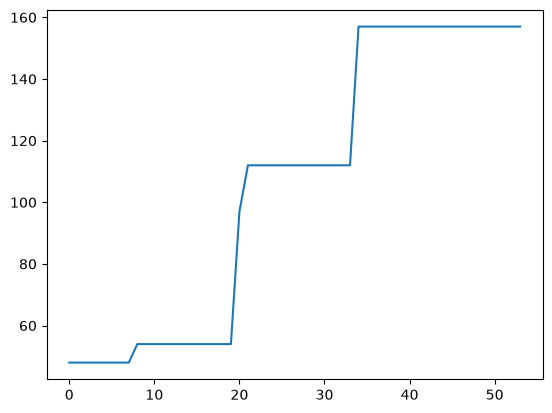

In [ ]:
# Stochastic Hill Climbing, repetition 3
from src.engine import *
from src.solvers.hill_climbing import Stochastic
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = pkgs_3
print("Packages List:", pkgs) # List of packages
# Truck(id, width, length, height, max_capacity)
trucks = trucks_3
print("Trucks List:", trucks) # List of trucks

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_stochastic = Stochastic(obj, max_random_successor_iterations=20, max_iterations = 100)
results_stochastic = solver_stochastic.solve(initial_state)

# Getting the results
print("Final State:", results_stochastic.final_state) # Output: Final State
print("Final Objective Value:", results_stochastic.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_stochastic.runtime, "sec") # Output: Runtime
print("Iterations:", results_stochastic.total_iterations) # Output: Iterations
print("Random Successor Iterations:", results_stochastic.metadata["random_successor_iterations"]) # Output: Random Successor Iterations
plt.plot(results_stochastic.objective_history) # Output: Plot of Objective Value over Iterations

Packages List: [Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3), Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1), Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2), Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4), Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5)]
Trucks List: [Truck a (dim=10x20x5, max_capacity=25), Truck b (dim=8x15x4, max_capacity=30)]
Initial States: [State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck a at (7, 8, 0)
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Unassigned
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Truck b at (4, 4, 0)
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Unassigned
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Truck b at (1, 11, 0)
, State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck a at (8, 10, 0)
  Package B (di

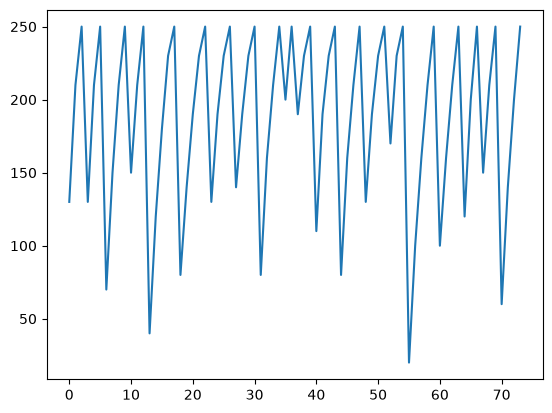

In [ ]:
# Random Restart Hill Climbing, repetition 1
from src.engine import *
from src.solvers.hill_climbing import RandomRestart
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = [
   # Package(id, width, length, height, value, weight, is_fragile, eta) 
   Package("A", 3, 4, 1, 60, 5, False, 3), 
   Package("B", 2, 2, 2, 40, 3, True, 1),
   Package("C", 1, 1, 1, 20, 1, False, 2),
   Package("D", 4, 5, 2, 80, 7, True, 4),
   Package("E", 2, 3, 1, 50, 4, False, 5)
]
print("Packages List:", pkgs) # List of packages
# Truck(id, width, length, height, max_capacity)
trucks = [Truck("a", 10, 20, 5, 25), Truck("b", 8, 15, 4, 30)]
print("Trucks List:", trucks) # List of trucks

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_random_restart = RandomRestart(obj, max_restarts=20, max_iterations_per_restart=100, initial_state=initial_state)
results_random_restart = solver_random_restart.solve()

# Getting the results
print("Initial States:", results_random_restart.initial_state) # Input: List of Random Initial States
print("Final State:", results_random_restart.final_state) # Output: Final State
print("Final Objective Value:", results_random_restart.metadata["final_objective_value"]) # Output: Final Objective Value
print("Runtime:", results_random_restart.runtime, "sec") # Output: Runtime
print("Total Restarts:", results_random_restart.metadata["total_restarts"]) # Output: Total Restarts
print("Iterations per Restart:", results_random_restart.metadata["iterations_per_restart"]) # Output: Iterations
plt.plot(results_random_restart.objective_history) # Output: Plot of Objective Value over Iterations

Packages List: [Package P1 (dim=4x1x5, weight=9, value=77, fragile=True, eta=5), Package P2 (dim=1x2x4, weight=8, value=56, fragile=False, eta=5), Package P3 (dim=2x4x3, weight=4, value=71, fragile=True, eta=5), Package P4 (dim=3x4x3, weight=6, value=19, fragile=False, eta=6), Package P5 (dim=2x2x4, weight=2, value=20, fragile=True, eta=6), Package P6 (dim=1x2x3, weight=10, value=66, fragile=False, eta=10), Package P7 (dim=3x4x4, weight=5, value=64, fragile=True, eta=3), Package P8 (dim=4x2x2, weight=5, value=41, fragile=False, eta=10), Package P9 (dim=5x2x2, weight=6, value=50, fragile=True, eta=10), Package P10 (dim=3x5x4, weight=8, value=78, fragile=True, eta=7), Package P11 (dim=2x5x3, weight=8, value=59, fragile=True, eta=3), Package P12 (dim=5x1x3, weight=10, value=78, fragile=True, eta=2), Package P13 (dim=5x4x4, weight=5, value=76, fragile=True, eta=4), Package P14 (dim=1x4x1, weight=5, value=57, fragile=False, eta=4), Package P15 (dim=2x1x1, weight=6, value=79, fragile=False, 

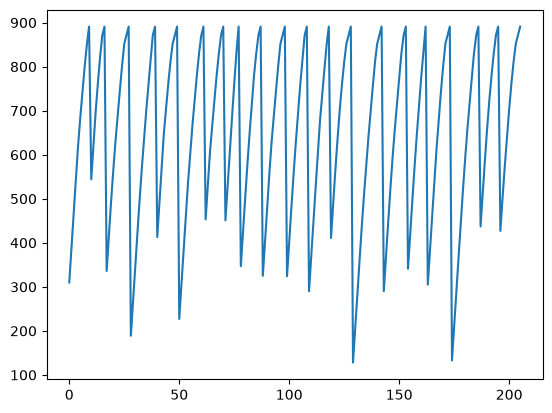

In [ ]:
# Random Restart Hill Climbing, repetition 2
from src.engine import *
from src.solvers.hill_climbing import RandomRestart
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = pkgs_2
print("Packages List:", pkgs) # List of packages
# Truck(id, width, length, height, max_capacity)
trucks = trucks_2
print("Trucks List:", trucks) # List of trucks

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_random_restart = RandomRestart(obj, max_restarts=20, max_iterations_per_restart=100, initial_state=initial_state)
results_random_restart = solver_random_restart.solve()

# Getting the results
print("Initial States:", results_random_restart.initial_state) # Input: List of Random Initial States
print("Final State:", results_random_restart.final_state) # Output: Final State
print("Final Objective Value:", results_random_restart.metadata["final_objective_value"]) # Output: Final Objective Value
print("Runtime:", results_random_restart.runtime, "sec") # Output: Runtime
print("Total Restarts:", results_random_restart.metadata["total_restarts"]) # Output: Total Restarts
print("Iterations per Restart:", results_random_restart.metadata["iterations_per_restart"]) # Output: Iterations
plt.plot(results_random_restart.objective_history) # Output: Plot of Objective Value over Iterations

Packages List: [Package P1 (dim=3x5x3, weight=6, value=72, fragile=True, eta=8), Package P2 (dim=3x1x5, weight=7, value=29, fragile=False, eta=6), Package P3 (dim=3x3x3, weight=6, value=85, fragile=False, eta=5), Package P4 (dim=1x2x3, weight=6, value=10, fragile=True, eta=5), Package P5 (dim=3x3x3, weight=5, value=19, fragile=True, eta=4), Package P6 (dim=2x4x5, weight=2, value=25, fragile=False, eta=7), Package P7 (dim=3x2x1, weight=6, value=40, fragile=True, eta=4)]
Trucks List: [Truck T1 (dim=10x18x8, max_capacity=40)]
Initial States: [State:
  Package P1 (dim=3x5x3, weight=6, value=72, fragile=True, eta=8) -> Unassigned
  Package P2 (dim=3x1x5, weight=7, value=29, fragile=False, eta=6) -> Truck T1 at (7, 0, 0)
  Package P3 (dim=3x3x3, weight=6, value=85, fragile=False, eta=5) -> Unassigned
  Package P4 (dim=1x2x3, weight=6, value=10, fragile=True, eta=5) -> Unassigned
  Package P5 (dim=3x3x3, weight=5, value=19, fragile=True, eta=4) -> Unassigned
  Package P6 (dim=2x4x5, weight=2,

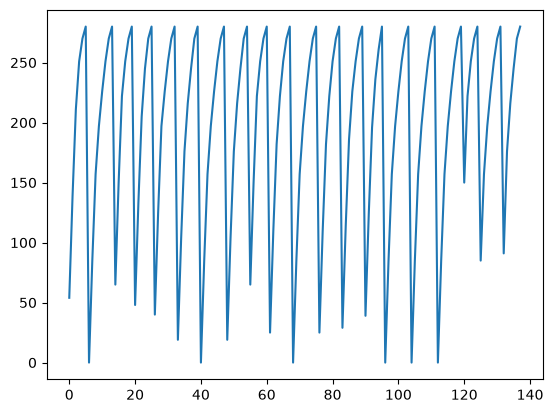

In [ ]:
# Random Restart Hill Climbing, repetition 3
from src.engine import *
from src.solvers.hill_climbing import RandomRestart
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = pkgs_3
print("Packages List:", pkgs) # List of packages
# Truck(id, width, length, height, max_capacity)
trucks = trucks_3
print("Trucks List:", trucks) # List of trucks

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_random_restart = RandomRestart(obj, max_restarts=20, max_iterations_per_restart=100, initial_state=initial_state)
results_random_restart = solver_random_restart.solve()

# Getting the results
print("Initial States:", results_random_restart.initial_state) # Input: List of Random Initial States
print("Final State:", results_random_restart.final_state) # Output: Final State
print("Final Objective Value:", results_random_restart.metadata["final_objective_value"]) # Output: Final Objective Value
print("Runtime:", results_random_restart.runtime, "sec") # Output: Runtime
print("Total Restarts:", results_random_restart.metadata["total_restarts"]) # Output: Total Restarts
print("Iterations per Restart:", results_random_restart.metadata["iterations_per_restart"]) # Output: Iterations
plt.plot(results_random_restart.objective_history) # Output: Plot of Objective Value over Iterations